### <font color="skyblue">The Constraint Minimization Problems:</font> ### 

The applications in the mixture distribution model are often formulated as constraint minimization problems. These problems involve finding the optimal parameters of the mixture model while satisfying certain constraints. The constraints can be related to the properties of the distributions, such as non-negativity, normalization, or specific relationships between the parameters.

##### <font color="yellow">Example:</font> $\beta$ <font color="yellow">mixture problem</font> #####

Estimate the parameters of $\beta$  mixture. Suppose a sample of size n come from a mixture of two $\beta$ distributions with pdf:

$f(x|\Omega)=\pi_1 \beta(x|a_1, b_1) + \pi_2 \beta(x|a_2, b_2)$  where

$\Omega = \{\pi_1, \pi_2, a_1, b_1, a_2, b_2|\pi_1 + \pi_2 =1\}$

We want to estimate the unknown parameters $\Omega$ by maximizing the log joint likelihood functions as shown

$\displaystyle \max_{\Omega = \{\pi_1, \pi_2, a_1, b_1, a_2, b_2|\pi_1 + \pi_2 =1, \pi_1, \pi_2, a_1, b_1, a_2, b_2 >0\}} \ln \Pi_{i=1}^{n} f(x_i|\Omega)$

The objective function is writtern as

$$L(\Omega) = \sum_{i=1}^n \ln(\pi_1 \beta(x_i|a_1, b_1) + \pi_2 \beta(x_i|a_2, b_2))$$

Things to do for this example:

1. Set up the scenario (the parameters)
1. Plot the graph of the popuplation pdf
1. Generate simulated sample of size $n$
1. Plot histogram of the simulatd sample
1. Solve the minimization for the parameters
1. Draw the mixture pdf on top of histogram





<font color=yellow>評估 MLE 估計的表現</font>：譬如從蒙地卡羅實驗中評估 MLE 的特色，如一致性（consistency）、有效性（efficiency）、偏誤（bias）等。這些特性可以透過以下指標來評估：


- Mean：N 次實驗的估計值的平均數，$Mean(\hat{\theta})=\frac{1}{N}\sum_{k=1}^{N} \hat{\theta}_k=\bar{\theta}$
- Bias：N 次實驗的估計值的平均數減去真實值，$Bias(\hat{\theta})=\bar{\theta}-\theta$
- RMSE (Root Mean Square Error)：N 次實驗的估計值的平方根平均誤差，$RMSE(\hat{\theta})=\sqrt{\frac{1}{N}\sum_{k=1}^{N} (\hat{\theta}_k - \theta)^2}$。
<hr>

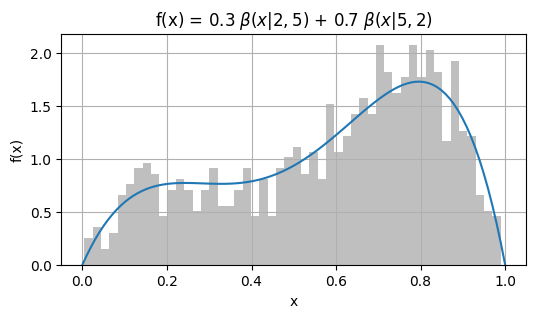

In [23]:
# draw f(x) = pi1 * beta(x|a1,b1) + pi2 * beta(x|a2,b2)

from scipy.stats import beta, binom
import numpy as np
import matplotlib.pyplot as plt

pi1 = 0.3
pi2 = 1 - pi1
a1, b1 = 2, 5
a2, b2 = 5, 2

f = lambda x: pi1 * beta.pdf(x, a1, b1) + pi2 * beta.pdf(x, a2, b2)
# generate n samples from the mixture of beta distributions
n = 1000
n1 = binom.rvs(n, pi1)
n2 = n - n1
sample1 = beta.rvs(a1, b1, size=n1)
sample2 = beta.rvs(a2, b2, size=n2)
samples = np.concatenate([sample1, sample2])

x = np.linspace(0, 1, 100)
y = f(x)

fig = plt.figure(figsize=(6, 3))
plt.plot(x, y)
# plot histogram of samples
plt.hist(samples, bins=50, density=True, alpha=0.5, color='gray')
# plt.title('Mixture of Beta Distributions')
plt.title(r'f(x) = {} $\beta(x| {}, {})$ + {} $\beta(x| {}, {})$'.format(pi1, a1, b1, pi2, a2, b2))
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.show()

In [25]:
# define the log-joint likelihood function for the mixture of beta distributions
from scipy.optimize import minimize

def log_joint_likelihood(params, data):
    pi1, a1, b1, a2, b2 = params
    pi2 = 1 - pi1
    # if pi1 < 0 or pi1 > 1 or a1 <= 0 or b1 <= 0 or a2 <= 0 or b2 <= 0:
    #     return -np.inf
    log_likelihood = np.sum(np.log(pi1 * beta.pdf(data, a1, b1) + \
                                   pi2 * beta.pdf(data, a2, b2)))
    return log_likelihood

# define the negative log-likelihood function for optimization
def neg_log_joint_likelihood(params, data):
    return -log_joint_likelihood(params, data)

# optimize the parameters
initial_params = (0.5, 1, 6, 6, 1)
result = minimize(neg_log_joint_likelihood, initial_params, \
                  args=(samples,), method='L-BFGS-B', \
                    bounds=[(0, 1), (0.001, None), (0.001, None), (0.001, None), (0.001, None)])
# print the estimated parameters
pi1_hat, a1_hat, b1_hat, a2_hat, b2_hat = result.x
print('Estimated parameters:')
print(f'pi1: {pi1_hat:.3f}, a1: {a1_hat:.3f}, b1: {b1_hat:.3f}, a2: {a2_hat:.3f}, b2: {b2_hat:.3f}')

Estimated parameters:
pi1: 0.282, a1: 1.882, b1: 5.124, a2: 5.505, b2: 2.176


##### <font color=yellow>Exercise: Normal mixture</font> #####

Similar to the previous example, the objective function is

$L(\Omega) = \sum_{i=1}^n \ln(\pi_1 N(x_i|\mu_1, \sigma^2_1) + \pi_2 N(x_i|\mu_2, \sigma^2_2))$

The optimization problem becomes

$\displaystyle \max_{\Omega = \{\pi_1, \pi_2, \mu_1, \sigma_1, \mu_2, \sigma_2|\pi_1 + \pi_2 =1,  \sigma_1 > 0, \sigma_2 >0\}} L(\Omega)$
